# 02 · Exploratory Data Analysis
Goal: understand **who buys, from where, and what they do on site before buying**, and pick up signals for the model.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

df = pd.read_csv("../data/processed/sessions_clean.csv", parse_dates=["session_start"])
os.makedirs("../images", exist_ok=True)

BLUE, ORANGE, GRAY, INK, MUTED = "#2a78d6", "#eb6834", "#b8b6ae", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#d7d5cd",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#ecebe6",
    "grid.linewidth": 0.8, "axes.axisbelow": True, "font.size": 10, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "text.color": INK,
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
})
BASE_RATE = df["purchased"].mean()

def conv_bar(col, title, fname, order=None, min_n=100):
    g = df.groupby(col)["purchased"].agg(["mean", "size"])
    g = g[g["size"] >= min_n]
    g = g.loc[order] if order else g.sort_values("mean")
    fig, ax = plt.subplots(figsize=(8, 0.42 * len(g) + 1.2))
    ax.barh(g.index.astype(str), g["mean"], color=BLUE, height=0.6)
    ax.axvline(BASE_RATE, color=MUTED, ls="--", lw=1, zorder=1)
    ax.text(BASE_RATE, len(g) - 0.4, f" overall {BASE_RATE:.1%}", color=MUTED, fontsize=9, va="bottom")
    for i, (m, n) in enumerate(zip(g["mean"], g["size"])):
        ax.text(m + 0.003, i, f"{m:.1%}  (n={n:,})", va="center", fontsize=9, color=INK,
                bbox=dict(facecolor="#fcfcfb", edgecolor="none", pad=1), zorder=3)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
    ax.set_xlim(0, g["mean"].max() * 1.35)
    ax.grid(axis="y", visible=False)
    ax.set_title(title)
    fig.tight_layout()
    fig.savefig(f"../images/{fname}", dpi=130, bbox_inches="tight")
    return g

print(f"{len(df):,} sessions | conversion rate {BASE_RATE:.1%}")

15,873 sessions | conversion rate 17.3%


## 1. Target balance
Only about 1 in 6 sessions converts → the classes are **imbalanced**. Accuracy alone would be misleading (a model that always says *"won't buy"* is ~83% accurate), so the model is judged on **F1, precision/recall and PR-AUC**.

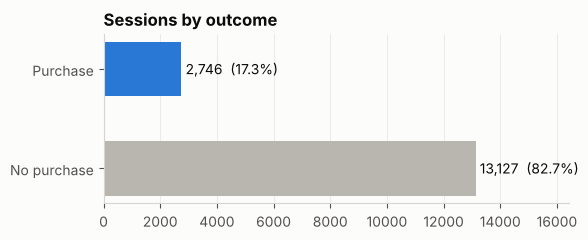

In [2]:
counts = df["purchased"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6, 2.2))
ax.barh(["No purchase", "Purchase"], counts.values, color=[GRAY, BLUE], height=0.55)
for i, v in enumerate(counts.values):
    ax.text(v + 150, i, f"{v:,}  ({v / len(df):.1%})", va="center")
ax.set_xlim(0, counts.max() * 1.25); ax.grid(axis="y", visible=False)
ax.set_title("Sessions by outcome")
fig.savefig("../images/01_target_balance.png", dpi=130, bbox_inches="tight")

## 2. Where do buyers come from?

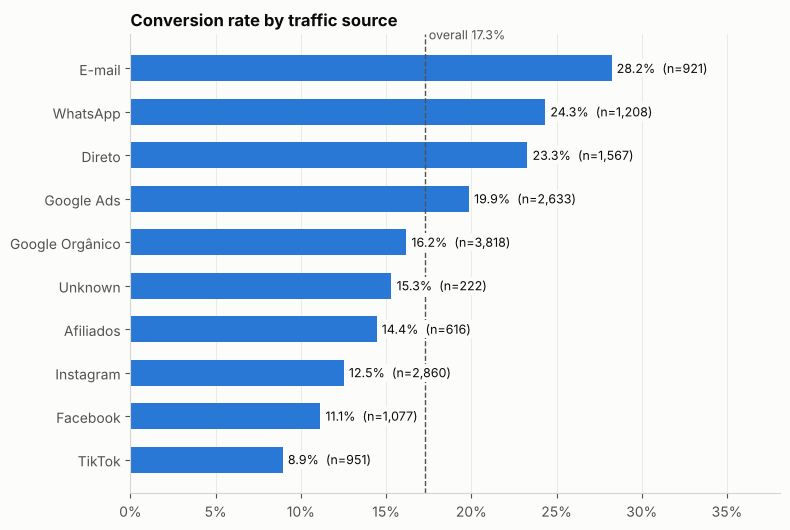

,mean,size
traffic_source,,
TikTok,0.089380,951
Facebook,0.111421,1077
Instagram,0.125175,2860
Afiliados,0.144481,616
Unknown,0.153153,222
Google Orgânico,0.161865,3818
Google Ads,0.198633,2633
Direto,0.232929,1567
WhatsApp,0.243377,1208


In [3]:
conv_bar("traffic_source", "Conversion rate by traffic source", "02_conv_by_source.png")

**Insight:** owned & relationship channels win. **E-mail (28%), WhatsApp (24%) and Direct (23%)** convert well above the 17% average, while social discovery channels (**TikTok 9%, Facebook 11%, Instagram 13%**) bring traffic that mostly browses. Instagram is the 2nd largest source, so improving it matters more than its rate suggests.

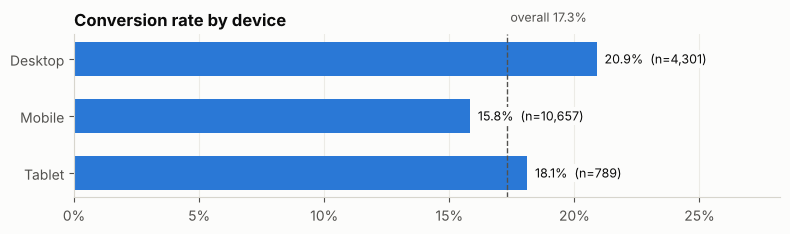

,mean,size
device_type,,
Tablet,0.181242,789
Mobile,0.158394,10657
Desktop,0.209021,4301


In [4]:
conv_bar("device_type", "Conversion rate by device", "03_conv_by_device.png",
         order=["Tablet", "Mobile", "Desktop"])

In [5]:
traffic_share = df["device_type"].value_counts(normalize=True)
traffic_share

,proportion
device_type,
Mobile,0.671392
Desktop,0.270963
Tablet,0.049707
Unknown,0.007938


**Insight:** two-thirds of sessions are on **mobile**, yet mobile converts at **15.8% vs 20.9% on desktop**. Checkout friction on mobile is the single biggest lever by volume.

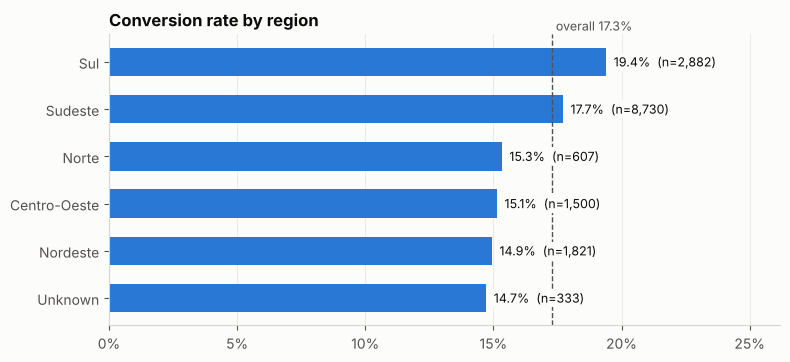

,mean,size
region,,
Unknown,0.147147,333
Nordeste,0.149368,1821
Centro-Oeste,0.151333,1500
Norte,0.153213,607
Sudeste,0.177090,8730
Sul,0.193963,2882


In [6]:
conv_bar("region", "Conversion rate by region", "04_conv_by_region.png")

**Insight:** South (19%) and Southeast (18%) convert better than North/Northeast/Centre-West (~15%), which is consistent with higher freight cost and longer delivery times outside the Sul–Sudeste axis.

## 3. Brazilian retail calendar

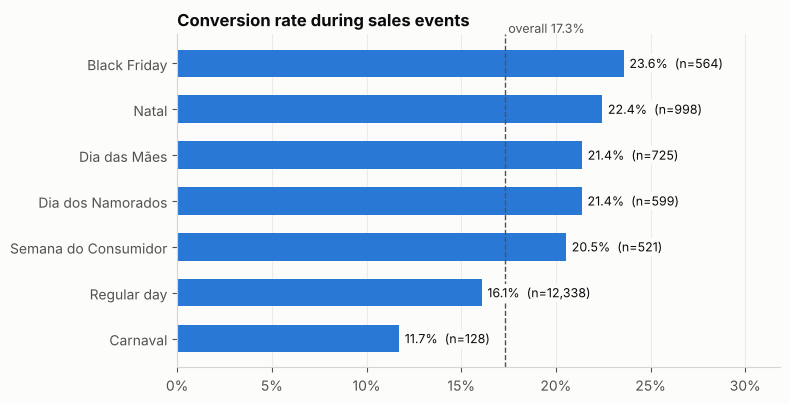

,mean,size
sales_event,,
Carnaval,0.117188,128
Regular day,0.160804,12338
Semana do Consumidor,0.205374,521
Dia dos Namorados,0.213689,599
Dia das Mães,0.213793,725
Natal,0.224449,998
Black Friday,0.235816,564


In [7]:
order = ["Carnaval", "Regular day", "Semana do Consumidor", "Dia dos Namorados", "Dia das Mães", "Natal", "Black Friday"]
conv_bar("sales_event", "Conversion rate during sales events", "05_conv_by_event.png", order=order, min_n=50)

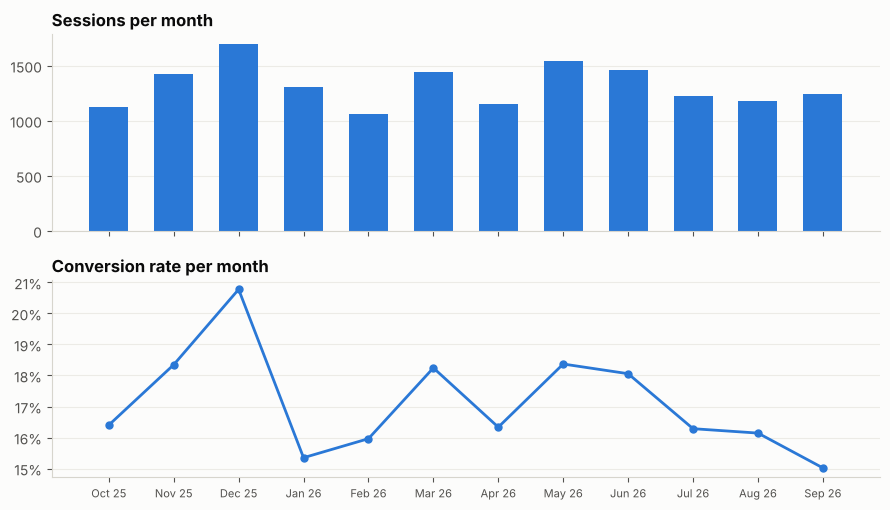

,size,mean
session_start,,
Oct 25,1128,0.164
Nov 25,1428,0.183
Dec 25,1699,0.208
Jan 26,1303,0.153
Feb 26,1065,0.160
Mar 26,1447,0.182
Apr 26,1151,0.163
May 26,1546,0.184
Jun 26,1462,0.181


In [8]:
monthly = (df.set_index("session_start").resample("MS")["purchased"].agg(["size", "mean"]))
monthly.index = monthly.index.strftime("%b %y")
fig, axes = plt.subplots(2, 1, figsize=(9, 5.2), sharex=True)
axes[0].bar(monthly.index, monthly["size"], color=BLUE, width=0.6)
axes[0].set_title("Sessions per month"); axes[0].grid(axis="x", visible=False)
axes[1].plot(monthly.index, monthly["mean"], color=BLUE, lw=2, marker="o", ms=5)
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
axes[1].set_title("Conversion rate per month"); axes[1].grid(axis="x", visible=False)
plt.xticks(rotation=0, fontsize=8)
fig.tight_layout()
fig.savefig("../images/06_monthly_trend.png", dpi=130, bbox_inches="tight")
monthly.round(3)

**Insight:** **Black Friday (23.6%)** and **Natal (22.4%)** lift conversion ~40% above a regular day, December is the strongest month, and Carnaval week is the weakest. The calendar should be a model feature, and campaign budgets should follow it.

## 4. On-site behaviour: the micro-conversions
Brazilian shoppers check **frete** (shipping cost) and **parcelamento** (installments, e.g. *"10x sem juros"*) before buying. Do these actions predict purchase?

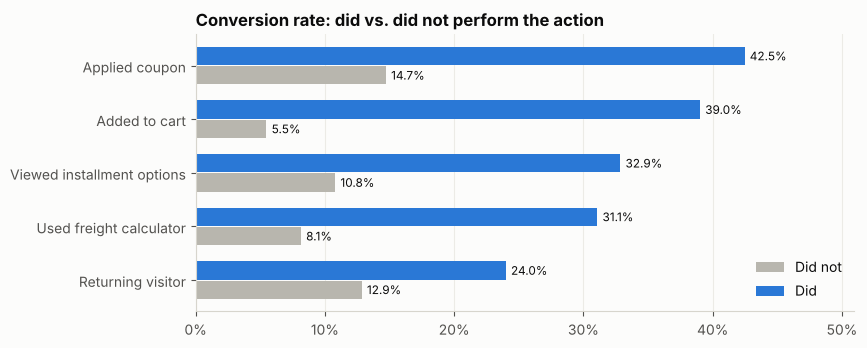

,did,did_not,share_of_sessions,lift
action,,,,
Returning visitor,0.240,0.129,0.399,1.867
Used freight calculator,0.311,0.081,0.399,3.814
Viewed installment options,0.329,0.108,0.295,3.042
Added to cart,0.390,0.055,0.352,7.125
Applied coupon,0.425,0.147,0.093,2.885


In [9]:
actions = {
    "Added to cart": df["add_to_cart_count"] > 0,
    "Viewed installment options": df["viewed_installment_options"] == 1,
    "Used freight calculator": df["viewed_freight_calculator"] == 1,
    "Applied coupon": df["coupon_applied"] == 1,
    "Returning visitor": df["visitor_type"] == "Returning",
}
rows = []
for name, m in actions.items():
    rows.append({"action": name, "did": df.loc[m, "purchased"].mean(), "did_not": df.loc[~m, "purchased"].mean(),
                 "share_of_sessions": m.mean()})
act = pd.DataFrame(rows).set_index("action").sort_values("did")
act["lift"] = act["did"] / act["did_not"]

fig, ax = plt.subplots(figsize=(8.5, 3.6))
y = np.arange(len(act))
ax.barh(y - 0.18, act["did_not"], height=0.34, color=GRAY, label="Did not")
ax.barh(y + 0.18, act["did"], height=0.34, color=BLUE, label="Did")
for i, (a, b) in enumerate(zip(act["did_not"], act["did"])):
    ax.text(a + 0.004, i - 0.18, f"{a:.1%}", va="center", fontsize=8.5)
    ax.text(b + 0.004, i + 0.18, f"{b:.1%}", va="center", fontsize=8.5)
ax.set_yticks(y, act.index); ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set_xlim(0, act["did"].max() * 1.2)
ax.legend(frameon=False, loc="lower right"); ax.set_title("Conversion rate: did vs. did not perform the action")
fig.savefig("../images/07_micro_conversions.png", dpi=130, bbox_inches="tight")
act.round(3)

**Insight:** adding to cart is the strongest single signal (39% vs 5.5%), but the Brazil-specific steps are close behind: visitors who check the **freight calculator convert 3.8× more** and those who open **installment options convert 3× more**. These are moments where an on-site nudge (free-shipping threshold, *"12x sem juros"* banner) can tip a hesitant buyer.

## 5. Numeric features: buyers vs. non-buyers

In [10]:
num_cols = ["pages_viewed", "product_pages", "searches", "session_duration_sec", "product_page_duration_sec",
            "page_value_brl", "cart_value_brl", "bounce_rate", "exit_rate", "wishlist_adds"]
df.groupby("purchased")[num_cols].median().T.rename(columns={0: "median_no_purchase", 1: "median_purchase"})

purchased,median_no_purchase,median_purchase
pages_viewed,7.0000,11.00000
product_pages,3.0000,6.00000
searches,1.0000,1.00000
session_duration_sec,244.0000,372.00000
product_page_duration_sec,86.0000,189.00000
page_value_brl,0.0000,43.79500
cart_value_brl,0.0000,202.33000
bounce_rate,0.1635,0.11150
exit_rate,0.2910,0.25995
wishlist_adds,0.0000,0.00000


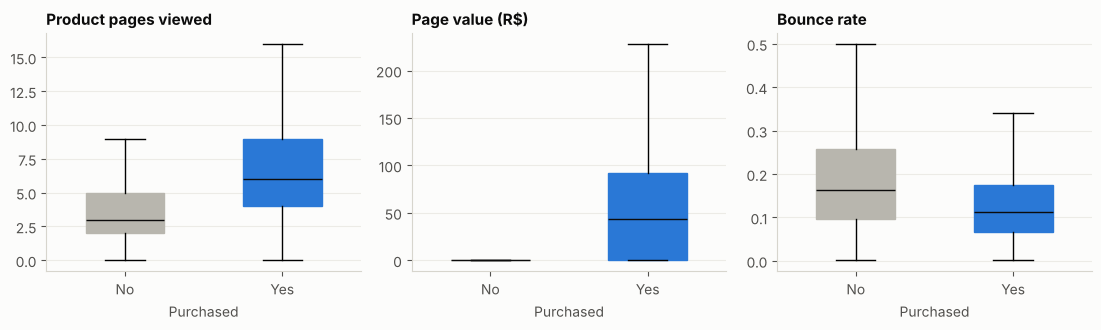

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
for ax, col, title in zip(axes, ["product_pages", "page_value_brl", "bounce_rate"],
                          ["Product pages viewed", "Page value (R$)", "Bounce rate"]):
    data = [df.loc[df.purchased == 0, col], df.loc[df.purchased == 1, col]]
    bp = ax.boxplot(data, tick_labels=["No", "Yes"], showfliers=False, patch_artist=True, widths=0.5,
                    medianprops=dict(color=INK))
    for patch, c in zip(bp["boxes"], [GRAY, BLUE]):
        patch.set_facecolor(c); patch.set_edgecolor(c)
    ax.set_title(title, fontsize=11); ax.set_xlabel("Purchased"); ax.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig("../images/08_numeric_by_target.png", dpi=130, bbox_inches="tight")

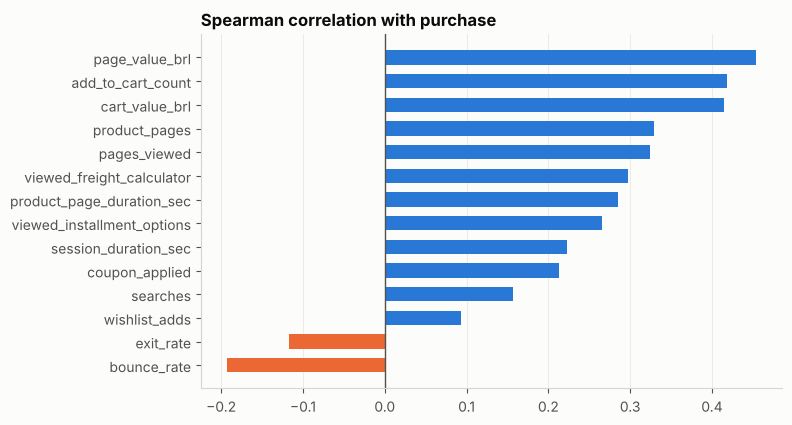

,purchased
bounce_rate,-0.193
exit_rate,-0.117
wishlist_adds,0.093
searches,0.156
coupon_applied,0.213
session_duration_sec,0.222
viewed_installment_options,0.266
product_page_duration_sec,0.285
viewed_freight_calculator,0.297
pages_viewed,0.324


In [12]:
corr = df[num_cols + ["viewed_freight_calculator", "viewed_installment_options", "coupon_applied",
                      "add_to_cart_count", "purchased"]].corr(method="spearman")["purchased"].drop("purchased")
corr = corr.sort_values()
fig, ax = plt.subplots(figsize=(7.5, 4.6))
ax.barh(corr.index, corr.values, color=[ORANGE if v < 0 else BLUE for v in corr.values], height=0.6)
ax.axvline(0, color=MUTED, lw=1); ax.grid(axis="y", visible=False)
ax.set_title("Spearman correlation with purchase")
fig.savefig("../images/09_correlation.png", dpi=130, bbox_inches="tight")
corr.round(3)

**Insight:** buyers look at **twice as many product pages** (6 vs 3) and spend **2× longer on product pages**, while bounce/exit rates are lower. `page_value_brl`, cart value and add-to-cart count have the highest rank correlation with purchase.

## Summary for the client
1. **Channels:** E-mail and WhatsApp convert best → grow the opt-in base; social traffic needs retargeting rather than more spend at the top.
2. **Mobile gap:** 67% of traffic, lowest conversion → prioritise mobile checkout UX.
3. **Frete & parcelamento:** checking shipping or installments is a strong buying signal → trigger targeted nudges at that moment.
4. **Calendar:** Black Friday, Natal and Dia das Mães are peak windows; Carnaval is a slow week.
5. **For modelling:** keep behavioural features, add calendar & channel features, handle the 17/83 class imbalance.